## Setup Colab

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ray[rllib] vizdoom opencv-python torch

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 952.1/952.1 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.9/38.9 MB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.2/74.2 MB 9.3 MB/s eta 0:00:00


In [3]:
import os
import csv
import ray
import gymnasium as gym
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt

from IPython.display import clear_output
from ray.tune.registry import register_env
from ray.rllib.algorithms.ppo import PPOConfig

In [4]:
ray.shutdown()
ray.init(num_gpus=1)
print(ray.cluster_resources())

BASE = "/content/drive/MyDrive/RL/Project/ppo_run1"
os.makedirs(f"{BASE}/checkpoints", exist_ok=True)
os.makedirs(f"{BASE}/videos", exist_ok=True)

2026-07-23 11:45:57,143	INFO worker.py:2024 -- Started a local Ray instance.


{'node:__internal_head__': 1.0, 'CPU': 2.0, 'object_store_memory': 3975199948.0, 'node:172.28.0.12': 1.0, 'memory': 9275466548.0, 'accelerator_type:T4': 1.0, 'GPU': 1.0}


## Universal Reusable Functions

In [5]:
def make_env_factory(vizdoom_env_name):
    def make_env(cfg):
        import vizdoom.gymnasium_wrapper
        import tempfile, os
        os.chdir(tempfile.mkdtemp())
        class W(gym.ObservationWrapper):
            def __init__(self, env, size=64):
                super().__init__(env)
                self.observation_space = gym.spaces.Box(0, 255, (size, size, 3), dtype=np.float32)
                self.size = size
            def observation(self, obs):
                return cv2.resize(obs["screen"], (self.size, self.size), interpolation=cv2.INTER_AREA).astype(np.float32)
        env = W(gym.make(vizdoom_env_name), size=64)
        env = gym.wrappers.TimeLimit(env, max_episode_steps=2100)  # FIX: TakeCover non ha timeout nativo, episodi infiniti causano OOM
        return env
    return make_env

def smoke_test(vizdoom_env_name, n_iters=50, num_env_runners=2, num_envs_per_env_runner=2):
    reg_name = f"reg_{vizdoom_env_name}"
    register_env(reg_name, make_env_factory(vizdoom_env_name))

    config = (
        PPOConfig()
        .environment(reg_name)
        .framework("torch")
        .env_runners(num_env_runners=num_env_runners, num_envs_per_env_runner=num_envs_per_env_runner)
        .learners(num_gpus_per_learner=1)
        .training(train_batch_size=4000, minibatch_size=256, num_epochs=10, lr=3e-4,
                   vf_clip_param=300.0, entropy_coeff=0.01, gamma=0.99)
    )
    a = config.build_algo() if hasattr(config, "build_algo") else config.build()
    print(f"[{vizdoom_env_name}] BUILD OK")

    rewards, lens, iters = [], [], []
    for i in range(n_iters):
        r = a.train()
        er = r["env_runners"]
        rewards.append(er.get("episode_return_mean", float("nan")))
        lens.append(er.get("episode_len_mean", float("nan")))
        iters.append(i)
        print(f"iter {i}: reward_mean={rewards[-1]}, ep_len_mean={lens[-1]}")
        clear_output(wait=True)
        fig, ax1 = plt.subplots(figsize=(9, 4))
        ax2 = ax1.twinx()
        ax1.plot(iters, rewards, color="tab:blue", label="reward_mean")
        ax2.plot(iters, lens, color="tab:orange", label="ep_len_mean")
        ax1.set_xlabel("iterazione"); ax1.set_ylabel("reward_mean", color="tab:blue")
        ax2.set_ylabel("ep_len_mean", color="tab:orange")
        ax1.set_title(f"{vizdoom_env_name} — iter {i}/{n_iters}")
        fig.legend(loc="upper left"); plt.show()

    ckpt_path = a.save_to_path(f"{BASE}/checkpoints/{vizdoom_env_name}_smoke{n_iters}")
    print(f"[{vizdoom_env_name}] checkpoint salvato:", ckpt_path)

    with open(f"{BASE}/checkpoints/{vizdoom_env_name}_smoke{n_iters}_metrics.csv", "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["iter", "reward_mean", "ep_len_mean"])
        for i in range(len(rewards)):
            writer.writerow([i, rewards[i], lens[i]])
    print(f"[{vizdoom_env_name}] metriche salvate su Drive")

    return a, {"reward": rewards, "len": lens}

In [6]:
# reload checkpoint + save video
def load_for_video(vizdoom_env_name, n_iters=50):
    reg_name = f"reg_{vizdoom_env_name}"
    register_env(reg_name, make_env_factory(vizdoom_env_name))
    config = (
        PPOConfig()
        .environment(reg_name)
        .framework("torch")
        .env_runners(num_env_runners=0)
        .learners(num_gpus_per_learner=0)
        .training(vf_clip_param=300.0, entropy_coeff=0.01)
    )
    a = config.build_algo() if hasattr(config, "build_algo") else config.build()
    a.restore_from_path(f"{BASE}/checkpoints/{vizdoom_env_name}_smoke{n_iters}")
    print(f"[{vizdoom_env_name}] pesi caricati")
    return a

def record_hires_video(a, vizdoom_env_name, n_episodes=10, n_iters=None):
    import vizdoom.gymnasium_wrapper
    module = a.get_module()
    dist_cls = module.get_inference_action_dist_cls()
    all_frames, lengths = [], []
    for ep in range(n_episodes):
        raw_env = gym.make(vizdoom_env_name)
        obs_dict, info = raw_env.reset()
        steps = 0
        max_steps = raw_env.unwrapped.game.get_episode_timeout() or 2100
        for step in range(max_steps):
            screen = obs_dict["screen"]
            all_frames.append(screen.copy())
            obs_small = cv2.resize(screen, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32)
            obs_t = torch.from_numpy(obs_small).unsqueeze(0)
            out = module.forward_inference({"obs": obs_t})
            dist = dist_cls.from_logits(out["action_dist_inputs"])
            action = int(dist.to_deterministic().sample().item())
            obs_dict, r, term, trunc, info = raw_env.step(action)
            steps += 1
            if term or trunc:
                break
        lengths.append(steps)
        raw_env.close()
    print(f"[{vizdoom_env_name}] lunghezze episodi:", lengths)
    h, w = all_frames[0].shape[0], all_frames[0].shape[1]
    suffix = f"_iter{n_iters}" if n_iters is not None else ""
    out_path = f"{BASE}/videos/{vizdoom_env_name}_hires{suffix}.mp4"
    vw = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), 15, (w, h))
    for fr in all_frames:
        vw.write(cv2.cvtColor(fr, cv2.COLOR_RGB2BGR))
    vw.release()
    print(f"[{vizdoom_env_name}] video salvato:", out_path)

## Training

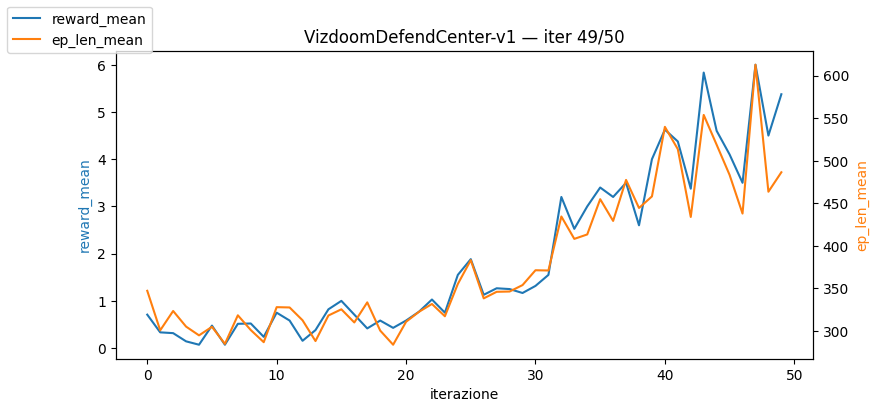

[VizdoomDefendCenter-v1] checkpoint salvato: /content/drive/MyDrive/RL/Project/ppo_run1/checkpoints/VizdoomDefendCenter-v1_smoke50
[VizdoomDefendCenter-v1] metriche salvate su Drive


In [ ]:
#training+ salva checkpoint + metriche
algo_dfc, metrics_dfc = smoke_test("VizdoomDefendCenter-v1", n_iters=50)

In [ ]:
record_hires_video(algo_dfc, "VizdoomDefendCenter-v1", n_episodes=10, n_iters=50)

[VizdoomDefendCenter-v1] lunghezze episodi: [789, 562, 706, 880, 586, 608, 560, 270, 461, 434]
[VizdoomDefendCenter-v1] video salvato: /content/drive/MyDrive/RL/Project/ppo_run1/videos/VizdoomDefendCenter-v1_hires.mp4


In [ ]:
#training metrics
for i in range(len(metrics_dfc["reward"])):
    print(f"iter {i}: reward_mean={metrics_dfc['reward'][i]}, ep_len_mean={metrics_dfc['len'][i]}")

iter 0: reward_mean=0.7083333333333334, ep_len_mean=347.08333333333337
iter 1: reward_mean=0.3333333333333333, ep_len_mean=300.625
iter 2: reward_mean=0.3166666666666667, ep_len_mean=323.3666666666667
iter 3: reward_mean=0.14285714285714285, ep_len_mean=305.0
iter 4: reward_mean=0.07142857142857142, ep_len_mean=294.7142857142857
iter 5: reward_mean=0.47619047619047616, ep_len_mean=304.76190476190476
iter 6: reward_mean=0.07142857142857142, ep_len_mean=284.7142857142857
iter 7: reward_mean=0.5142857142857142, ep_len_mean=318.2857142857143
iter 8: reward_mean=0.5208333333333333, ep_len_mean=300.95833333333337
iter 9: reward_mean=0.23809523809523808, ep_len_mean=286.6904761904762
iter 10: reward_mean=0.75, ep_len_mean=327.8571428571429
iter 11: reward_mean=0.5833333333333333, ep_len_mean=327.5
iter 12: reward_mean=0.15476190476190477, ep_len_mean=312.45238095238096
iter 13: reward_mean=0.38095238095238093, ep_len_mean=288.0238095238095
iter 14: reward_mean=0.8214285714285714, ep_len_mean=

## Load checkpoint

In [ ]:
algo_dfc.stop()

In [ ]:
# load checkpoint + video
algo_dfc_reloaded = load_for_video("VizdoomDefendCenter-v1", n_iters=50)
record_hires_video(algo_dfc_reloaded, "VizdoomDefendCenter-v1", n_episodes=10, n_iters="50_reload")

2026-07-22 09:18:03,408	WARNING rl_module.py:463 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., action_space=.., inference_only=.., model_config=.., catalog_class=..)` instead. This will raise an error in the future!
2026-07-22 09:18:10,407	WARNING util.py:62 -- Install gputil for GPU system monitoring.


[VizdoomDefendCenter-v1] pesi caricati
[VizdoomDefendCenter-v1] lunghezze episodi: [696, 542, 943, 545, 795, 948, 791, 810, 591, 487]
[VizdoomDefendCenter-v1] video salvato: /content/drive/MyDrive/RL/Project/ppo_run1/videos/VizdoomDefendCenter-v1_hires.mp4
